
# CB 3, Stat 4770/7770, Fall 2026
 
September 2026


Introduction

* In this homework you will download and read in a csv file that contains race times for a local 5K road running race. 
* The file includes finishing times together with the sex and age of the runner.
* You will summarize the file both numerically and graphically.

## Q1. Read in and review the data structure
### 5 pts.

> The data file is called "Run5K.csv".

a. Download the the data from the Canvas "Data sets" folder, to your computer and then into a pandas DataFrame. Call the data frame "run_data".

b. Use the shape attribute to find the number of rows and columns in the data frame.

c. Print out the column names.

d. Print out and review the data types for the columns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

import warnings
warnings.filterwarnings("ignore")

# Q1 
#1a. (1pt.)

run_data = pd.read_csv("Run5K.csv")

#1b. (1pt.)

print("1b: " + str(run_data.shape))

#1c. (2pts.) 

print("\n1c: " + str(run_data.columns))

#1d. (1pt.)

print("\n1c: " + str(run_data.dtypes))


1b: (501, 4)

1c: Index(['Time_mins', 'Time_secs', 'SEX', 'AGE'], dtype='str')

1c: Time_mins    int64
Time_secs    int64
SEX            str
AGE          int64
dtype: object


## Q2. Create a new column called "Finish_Time"
### 6pts.

You might have noticed that there are two columns containing the race time. One contains the minutes, and the other the seconds.

a. Create a *new* column in the run_data data frame called "Finish_Time" by adding minutes to seconds/60. As pandas is vectorized, you should be able to write a simple arithmetic expression involving the two time columns. There is no need for a for loop here. 

b. Calculate and print the average finish time of all participants. 

c. Print the average finish time for males and for females (use the groupby method). Remember that Python is case sensitive!

d. Save the result from the groupby in 2c into a variable called "mf_avs", and using this variable calculate and print the difference between the average finish times. 

In [2]:
#2a. (1pt.) 

run_data["Finish_Time"] = run_data["Time_mins"] + run_data["Time_secs"]/60

print("2a: " + str(run_data.head()))

#2b. (1pt.)

print("\n2b: " + str(sum(run_data["Finish_Time"])/len(run_data["Finish_Time"])))

#2c. (2pts.)

print("\n2c: " + str(run_data.groupby("SEX")["Finish_Time"].mean()))

#2d. (2pts.)

mf_avs = run_data.groupby("SEX")["Finish_Time"].mean()

print("\n2d: " + str(mf_avs["F"] - mf_avs["M"]))


2a:    Time_mins  Time_secs SEX  AGE  Finish_Time
0         15         23   M   21    15.383333
1         15         27   M   21    15.450000
2         15         33   M   20    15.550000
3         15         42   M   19    15.700000
4         15         48   M   19    15.800000

2b: 26.549467731204256

2c: SEX
F    29.615881
M    24.660161
Name: Finish_Time, dtype: float64

2d: 4.955720036029948


## Q3 Bucket the age variable into groups 
### 7pts.

In the class notes we used the 'qcut' function to bucket the "Schedule lag" data. In this question you should use the 'cut' command with age groups defined by these cutpoints: 

[0,16,25,30,35,40,45,50,55,60,65,70]

a. Add the discretized Age variable to the run_data data frame and call the new column "Disc_Age". You will use the pd.cut function to build the new variable with the above "bins" to do this.

b. Using 'groupby' again, find the average finish time by the 'Disc_Age' variable. 

c. Finally print the average finish time by the joint levels of SEX and Disc_Age.

d. Using the results of part c, comment on how finish times vary by age, between men and women. That is, who does aging seem to impact the most?

e. Using your answer to part c, pull out and print just the mean finish times for men and women, aged (40, 45].
Hint: use the '.index.values' attribute to see just exactly what is in the MultiIndex returned with part c.
Then use the .xs() method to extract using the appropriate label of the MultiIndex. This question is meant to involve you doing a bit of your own research to figure out how to do it!

In [3]:
#3a. (1pt.)

run_data["Disc_Age"] = pd.cut(run_data["AGE"], bins = [0,16,25,30,35,40,45,50,55,60,65,70])

#3b. (1pt.)

print("3b: " + str(run_data.groupby("Disc_Age")["Finish_Time"].mean()))

#3c. (1pt.)

print("\n3c: " + str(run_data.groupby(["SEX", "Disc_Age"])["Finish_Time"].mean()))

#3d. (1pt.) Your comment here.

print("\n3d: Men start out as faster than women, as seen by the starting times (29.667 for women and 24.175 for men); however, men slow down at a much faster rate than women, since both men and women end around 30, but men started lower sothey slowed down faster")

#3e. (3pts.) 

mean = run_data.groupby(["SEX", "Disc_Age"])["Finish_Time"].mean()

print("\n3e: " + str(mean.xs(key=pd.Interval(40, 45, closed='right'), level='Disc_Age')))

3b: Disc_Age
(0, 16]     25.981050
(16, 25]    23.422764
(25, 30]    27.127778
(30, 35]    27.760417
(35, 40]    27.332804
(40, 45]    27.378019
(45, 50]    27.194118
(50, 55]    26.891667
(55, 60]    28.171429
(60, 65]    28.144444
(65, 70]    30.444444
Name: Finish_Time, dtype: float64

3c: SEX  Disc_Age
F    (0, 16]     29.667361
     (16, 25]    28.333333
     (25, 30]    29.104861
     (30, 35]    30.281159
     (35, 40]    29.875758
     (40, 45]    30.514744
     (45, 50]    29.885833
     (50, 55]    28.586111
     (55, 60]    30.223333
M    (0, 16]     24.175510
     (16, 25]    20.589744
     (25, 30]    23.173611
     (30, 35]    25.441333
     (35, 40]    24.535556
     (40, 45]    25.481395
     (45, 50]    26.072569
     (50, 55]    26.468056
     (55, 60]    27.031481
     (60, 65]    28.144444
     (65, 70]    30.444444
Name: Finish_Time, dtype: float64

3d: Men start out as faster than women, as seen by the starting times (29.667 for women and 24.175 for men); however,

## Q4 Explore the distribution of finish time
### 6pts.

> In the following questions the idea is to now use seaborn to graphically summarize the data.  

a. Use the seaborn 'sns.displot' function to obtain a histogram of the finishing times.

b. Change the color of the plot to green, and add the KDE. If you use the command 'plt.show()' after each histogram, you can get all the plots showing in the cell. If you don't then depending on how Jupyter is set up, you will only see the last one.


4a:



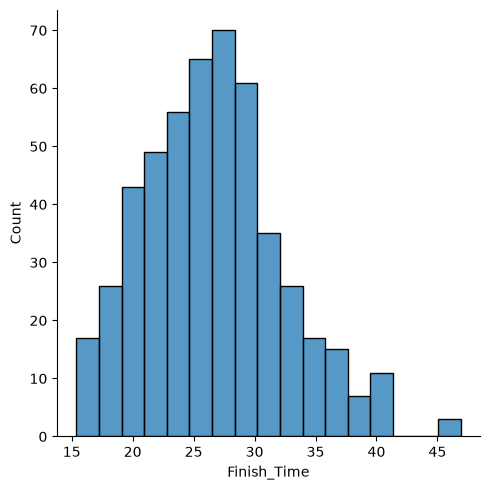


4b:



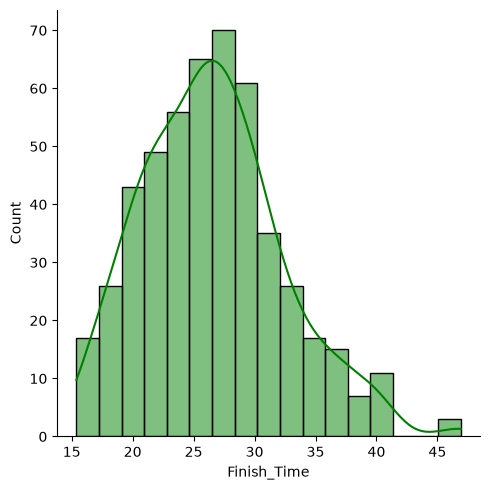

In [4]:
#4a. (3pts.)
print("4a:\n")
sns.displot(run_data["Finish_Time"]);
plt.show()
#4b. (3pts.)
print("\n4b:\n")
sns.displot(run_data["Finish_Time"], color = "green", kde = True);
plt.show()

## Q5 Comparing finishing time distributions for men and women
### 6 pts.

Use the 'sns.catplot' command to produce the required plots for this question.

a. Make a 'box plot' of the finishing time, over the levels of Sex. Orient this plot vertically using the 'orient' argument. 

b. Turn the graph into a violin plot, still vertically orientated and plot it.

5a:



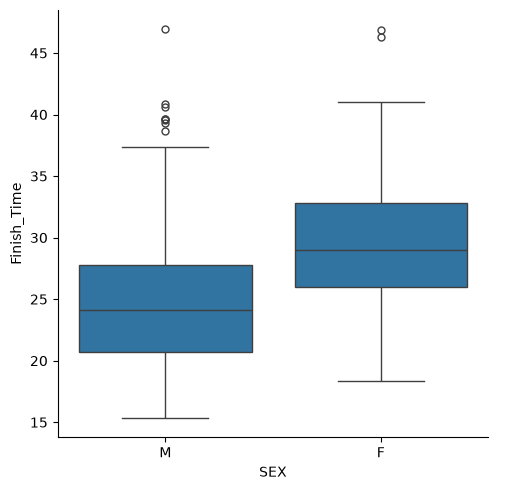

5b:



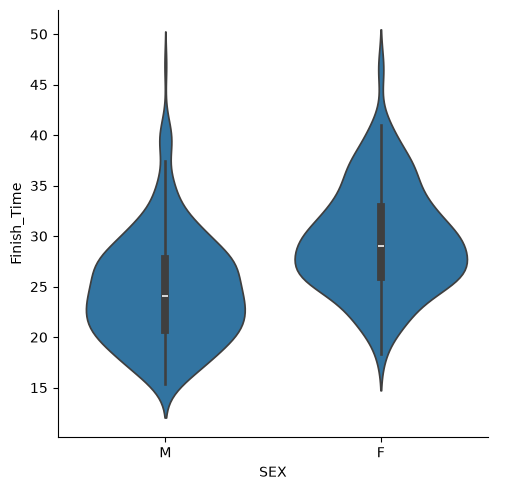

In [5]:
#5a. (3pts.)
print("5a:\n")
sns.catplot(data = run_data, y = "Finish_Time", x = "SEX", orient="v" , kind="box");
plt.show()

#5b. (3pts.)
print("5b:\n")
sns.catplot(data = run_data, y = "Finish_Time", x = "SEX", orient="v" , kind="violin");
plt.show()

## Q6. Bringing age into the mix
### 6 pts.
These questions should use the 'relplot' command in seaborn. Use the continuous version of the AGE variable for now.

a. Plot finish time against AGE. Use the 'height=6, aspect=2' arguments to 'relplot' to make the plot wider.)

b. Add SEX as the hue to the previous plot and display the new plot. 

6a:



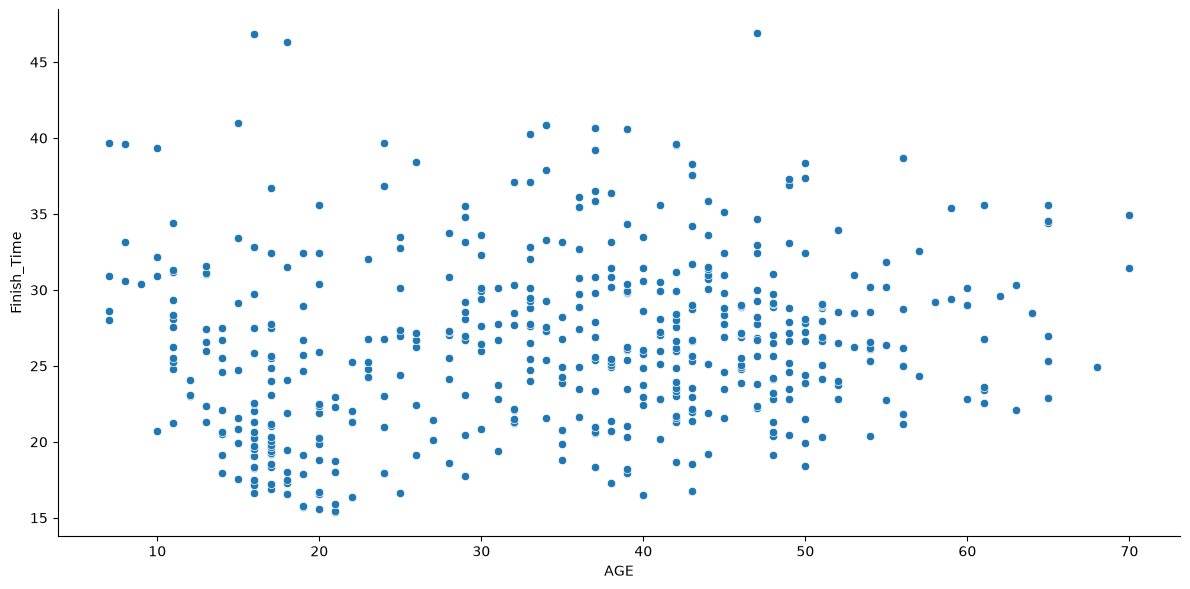

6b:



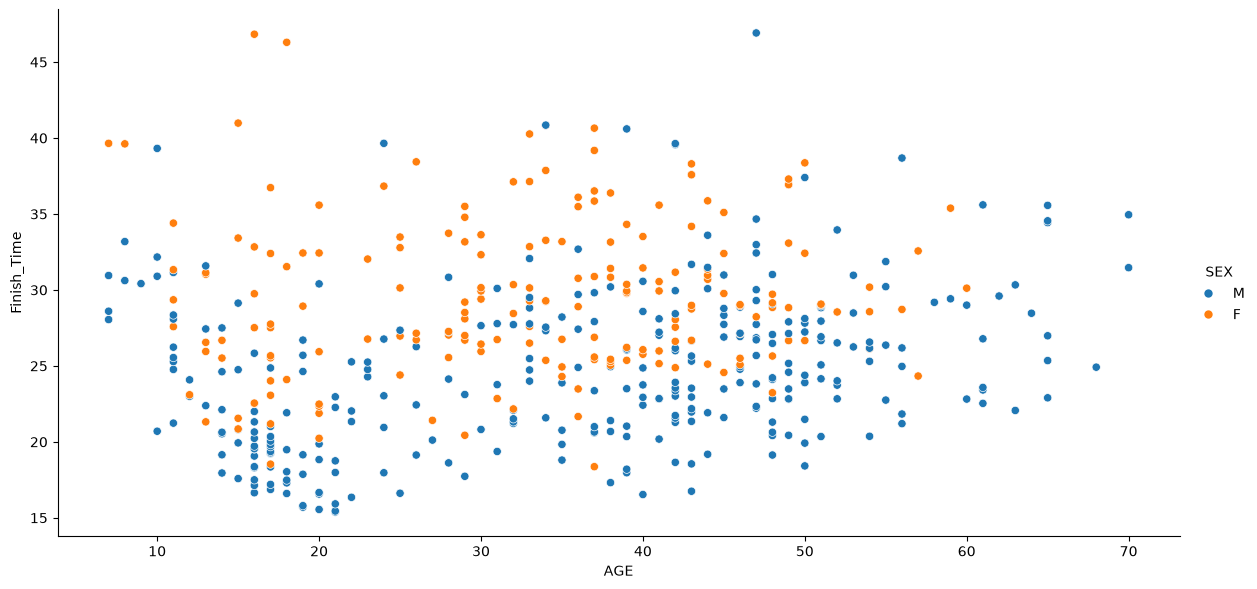

In [10]:
#6a. (3pts.)
print("6a:\n")
sns.relplot(data = run_data, y = "Finish_Time", x = "AGE", height = 6, aspect = 2);
plt.show()

#6b. (3pts.)
print("6b:\n")
sns.relplot(data = run_data, y = "Finish_Time", x = "AGE", hue = "SEX", height = 6, aspect = 2);
plt.show()

## Q7. Counting the number of people in each age bucket, by SEX
### 6 pts.

a. Use the sns.catplot command, with kind='count' to create a graphic that shows the number of runners in each age category, for the two sexes. You don't need a y-variable here, and use the col="SEX" to get two **separate** graphs. 

b. Now create the same graph, but this time rotating the x-axis labels and using a **different** color palette of your choice. Just make sure that the results are clearly visible.

c. Comment on the difference in age distribution between male and female runners.

7a:



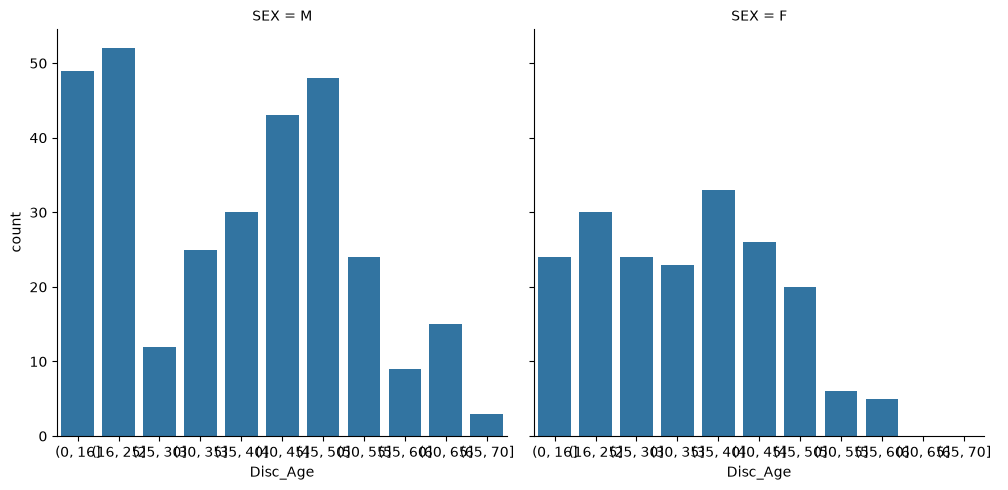


7b:



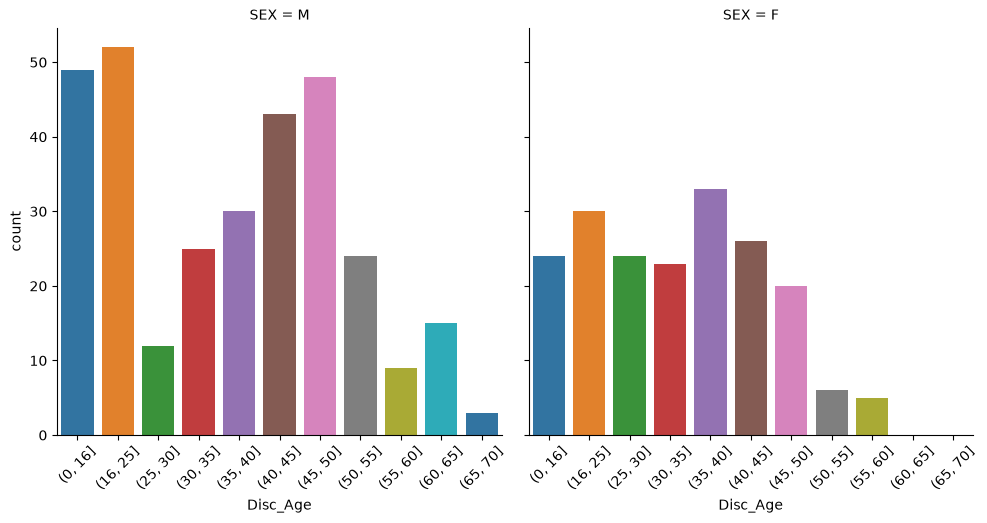


7c: There is a bimodal distribution of male runner ages, 
with many young and middle age runners, while there is a more uniform distribution of female runners.
There are also more runners in general for the men for most ages.



In [7]:
#7a. (2pts.)
print("7a:\n")
sns.catplot(data = run_data, x = "Disc_Age", col = "SEX", kind = "count");
plt.show()

#7b. (2pts.)
print("\n7b:\n")
sns.catplot(data = run_data, x = "Disc_Age", col = "SEX", kind = "count", palette = "tab10").set_xticklabels(rotation=45);
plt.show()

#7c. (2pts.) You answer here. 

print("""
7c: There is a bimodal distribution of male runner ages, 
with many young and middle age runners, while there is a more uniform distribution of female runners.
There are also more runners in general for the men for most ages.
""")



## Q8. Plot the mean finish time by age bucket and gender
### 5 pts.

a. Using the sns.catplot command again with 'Finish_Time' as the y-variable, plot the mean finish time (using kind="bar" or kind = "point" will do this), over the **discrete** age groups, with the additional argument 'hue = "SEX"' to obtain a single plot. Use the 'height=6, aspect=2' arguments again to widen the plot. (This will create an appropriate graph for the summaries you calculated in Q3).

b. Comment on the difference in average finish time between men and women as they age.

8a:



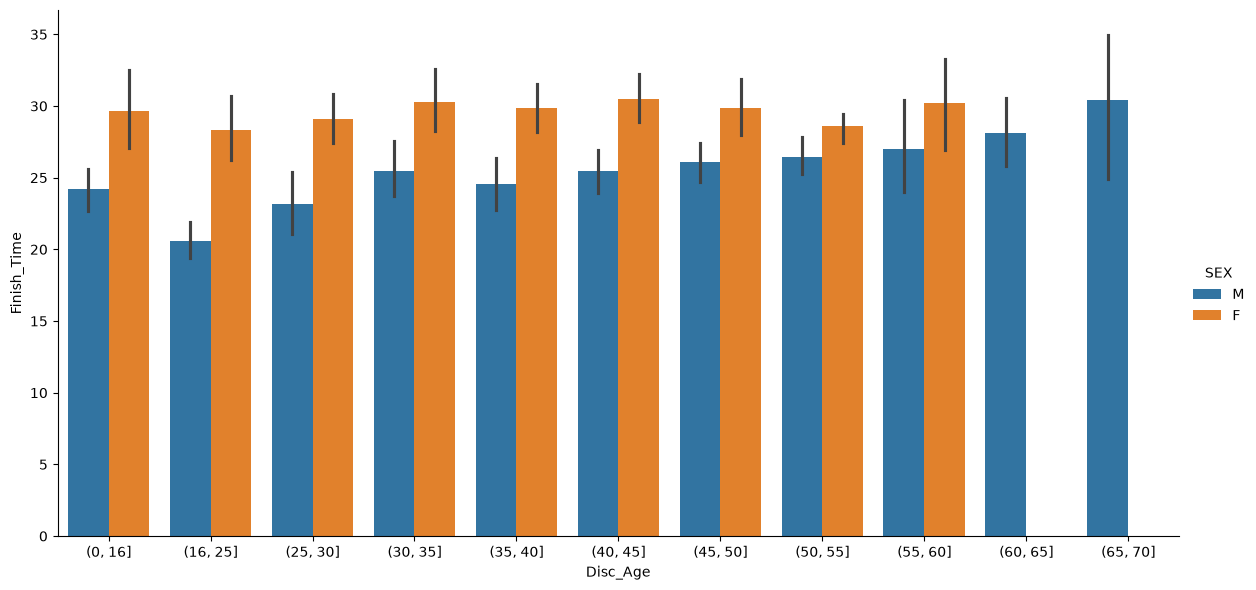


8b: The difference between men and women's average finish timeas they age is large in early ages on but gradually decreases as they age.


In [8]:
#Q8a. (3pts.)
print("8a:\n")
sns.catplot(data = run_data, x = "Disc_Age", y = "Finish_Time", kind = "bar", hue = "SEX", height = 6, aspect = 2);
plt.show()
#Q8b. (2pts.) Your comment here.
print("\n8b: The difference between men and women's average finish timeas they age is large in early ages on but gradually decreases as they age.")


## Q9. Make a mosaic plot of Sex by Age 
### 3 pts.

a. Using the statsmodel package, create a mosaic plot that shows the proportion of men and women in each *age bucket*. (Make sure you have an up-to-date version of statsmodels to do this if you downloaded Anaconda prior to this semester).

b. Write a sentence that describes what you learn from the mosaic plot.  

9a:



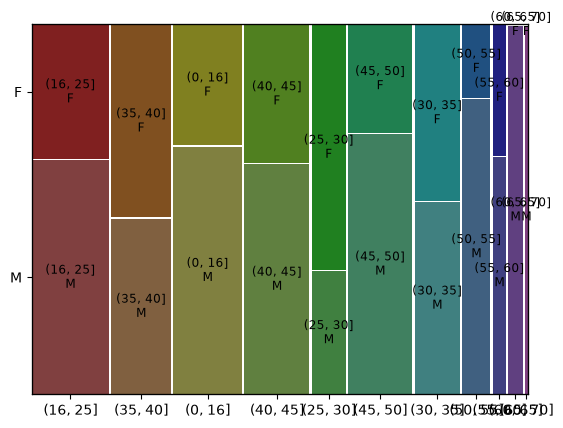


9b: The mosaic plot shows that the proportion of most of the ages below 55 is primarily men,
with a few exceptions of more women, such as 35,40 and 25,30. However, after 55, 
there are only women. There is more data of younger populations for both sexes and sparce data 
on the older ages.


In [9]:
from statsmodels.graphics.mosaicplot import mosaic

#9a. (2pts.)
print("9a:\n")
mosaic(run_data, ['Disc_Age', 'SEX']);
plt.show()

#9b. (1pt.) Your answer here.
print("""\n9b: The mosaic plot shows that the proportion of most of the ages below 55 is primarily men,
with a few exceptions of more women, such as 35,40 and 25,30. However, after 55, 
there are only women. There is more data of younger populations for both sexes and sparce data 
on the older ages.""")